# NASA Kepler — MLP Neural Network (Sophisticated Model)

**Initial architecture:** 19 inputs → 32 ReLU hidden neurons → 1 binary output (scikit-learn `MLPClassifier`). Standardization and median imputation occur **inside each fold**. We select models by **validation F1** and also report precision, recall, accuracy and ROC-AUC.


In [ ]:
import time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import f1_score, precision_score, recall_score, accuracy_score, roc_auc_score
import joblib


DATA_DIR = Path("Kepler_Datasets")


def read_csv(filename):
    file_path = DATA_DIR / filename

    if not file_path.is_file():
        raise FileNotFoundError(
            f"Could not find {file_path.resolve()}"
        )

    return pd.read_csv(file_path)


X_train = read_csv("X_train.csv")
y_train = read_csv("y_train.csv")["target"].astype(int).to_numpy()
groups = read_csv("train_ids.csv")["kepid"].to_numpy()

assert len(X_train) == len(y_train) == len(groups)
assert X_train.shape[1] == 19
assert set(y_train) == {0, 1}


print(f"Training observations: {len(X_train):,}")
print(f"Features: {X_train.shape[1]}")
print(f"Distinct host stars: {pd.Series(groups).nunique():,}")
print("Target counts:", pd.Series(y_train).value_counts().to_dict())

Training observations: 7,662
Features: 19
Distinct host stars: 6,571
Target counts: {0: 3858, 1: 3804}


## 1. Neural network configuration

The initial network has one hidden layer of 32 neurons, ReLU activation, Adam optimizer, and L2 regularization (`alpha=0.01`). We train for **at most 90 iterations**. An internal early-stopping validation split is intentionally disabled, so model preprocessing and assessment are controlled by our own host-star-aware folds.

In [3]:
def make_mlp():
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("mlp", MLPClassifier(
            hidden_layer_sizes=(32,), activation="relu", solver="adam",
            alpha=0.01, learning_rate_init=0.001, batch_size=128,
            max_iter=90, n_iter_no_change=20, tol=1e-4,
            early_stopping=False, random_state=42
        )),
    ])

def evaluate(y_true, model, X):
    predicted = model.predict(X)
    probability = model.predict_proba(X)[:, 1]
    return {
        "F1": f1_score(y_true, predicted, zero_division=0),
        "Precision": precision_score(y_true, predicted, zero_division=0),
        "Recall": recall_score(y_true, predicted, zero_division=0),
        "Accuracy": accuracy_score(y_true, predicted),
        "ROC-AUC": roc_auc_score(y_true, probability)
    }

## 2. Five-fold training vs validation



In [4]:
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
rows = []
for fold, (train_idx, val_idx) in enumerate(cv.split(X_train, y_train, groups), start=1):
    model = make_mlp()
    model.fit(X_train.iloc[train_idx], y_train[train_idx])
    for split, idx in (("Training", train_idx), ("Validation", val_idx)):
        row = {"Fold": fold, "Split": split, "N": len(idx),
               "Iterations": model.named_steps["mlp"].n_iter_}
        row.update(evaluate(y_train[idx], model, X_train.iloc[idx]))
        rows.append(row)

fold_scores = pd.DataFrame(rows)
summary = fold_scores.groupby("Split")[["F1", "Precision", "Recall", "Accuracy", "ROC-AUC"]].mean()
summary = summary.loc[["Training", "Validation"]]
summary["F1 gap"] = summary.loc["Training", "F1"] - summary.loc["Validation", "F1"]
print("Mean cross-validation metrics:")
display(summary.round(4))
print("Scores on each fold:")
display(fold_scores.round(4))

C:\Users\ryanb\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (90) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Users\ryanb\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (90) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Users\ryanb\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (90) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Users\ryanb\AppD

Mean cross-validation metrics:


C:\Users\ryanb\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (90) reached and the optimization hasn't converged yet.
  warnings.warn(


,F1,Precision,Recall,Accuracy,ROC-AUC,F1 gap
Split,,,,,,
Training,0.8358,0.8051,0.8689,0.8305,0.9117,0.0096
Validation,0.8262,0.7956,0.8594,0.8204,0.9028,0.0096


Scores on each fold:


,Fold,Split,N,Iterations,F1,Precision,Recall,Accuracy,ROC-AUC
0,1,Training,6130,90,0.8418,0.8138,0.8718,0.8374,0.9144
1,1,Validation,1532,90,0.8218,0.7840,0.8633,0.8140,0.9017
2,2,Training,6130,90,0.8310,0.7990,0.8656,0.8251,0.9082
3,2,Validation,1532,90,0.8407,0.8090,0.8750,0.8355,0.9132
4,3,Training,6130,90,0.8344,0.8079,0.8626,0.8300,0.9103
5,3,Validation,1532,90,0.8192,0.7973,0.8423,0.8153,0.9040
6,4,Training,6129,90,0.8348,0.8024,0.8699,0.8290,0.9114
7,4,Validation,1533,90,0.8321,0.8123,0.8528,0.8291,0.9057
8,5,Training,6129,90,0.8369,0.8025,0.8745,0.8308,0.9141
9,5,Validation,1533,90,0.8172,0.7757,0.8633,0.8082,0.8895


## 3. Compare with the tuned Decision Tree baseline

Decision Tree validation scores come from the previously completed five-fold grouped evaluation. Compare validation scores rather than training scores.

,F1,Precision,Recall,Accuracy,ROC-AUC
Tuned Decision Tree,0.8154,0.8036,0.8283,0.8139,0.8834
Initial MLP,0.8262,0.7956,0.8594,0.8204,0.9028


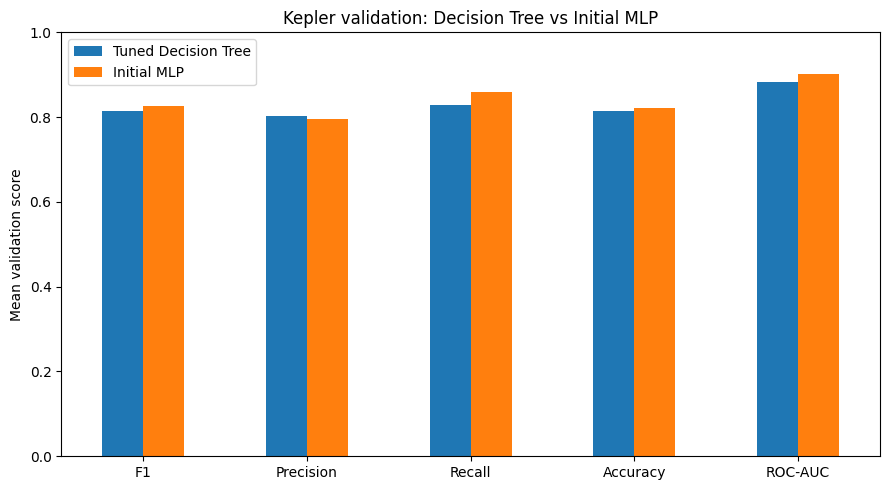

In [5]:
decision_tree = pd.Series({
    "F1": 0.8154, "Precision": 0.8036, "Recall": 0.8283,
    "Accuracy": 0.8139, "ROC-AUC": 0.8834
}, name="Tuned Decision Tree")
comparison = pd.DataFrame([decision_tree, summary.loc["Validation", decision_tree.index].rename("Initial MLP")])
comparison.index = ["Tuned Decision Tree", "Initial MLP"]
display(comparison.round(4))
ax = comparison[["F1", "Precision", "Recall", "Accuracy", "ROC-AUC"]].T.plot(kind="bar", figsize=(9,5))
ax.set_ylabel("Mean validation score")
ax.set_ylim(0, 1)
ax.set_title("Kepler validation: Decision Tree vs Initial MLP")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 4. Train a final initial-model pipeline on all training observations



In [6]:
final_model = make_mlp()
final_model.fit(X_train, y_train)
network = final_model.named_steps["mlp"]
parameter_count = sum(weight.size for weight in network.coefs_) + sum(bias.size for bias in network.intercepts_)
print("Full-training iterations:", network.n_iter_)
print("Trainable parameters:", parameter_count)
print("Network layers:", [weight.shape for weight in network.coefs_])
joblib.dump(final_model, "kepler_mlp_model.joblib")
fold_scores.to_csv("mlp_all_fold_scores.csv", index=False)
summary.to_csv("mlp_train_vs_validation.csv")
comparison.to_csv("mlp_vs_decision_tree.csv")
print("Saved model and metrics in the current directory.")

Full-training iterations: 90
Trainable parameters: 673
Network layers: [(19, 32), (32, 1)]
Saved model and metrics in the current directory.


C:\Users\ryanb\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (90) reached and the optimization hasn't converged yet.
  warnings.warn(
